# Глубинное обучение 1 / Введение в глубинное обучение, ФКН ВШЭ

## Домашнее задание 2: сверточный классификатор.

### Общая информация

Оценка после штрафа после мягкого дедлайна вычисляется по формуле $M_{\text{penalty}} = M_{\text{full}} \cdot 0.85^{t/1440}$, где $M_{\text{full}}$ — полная оценка за работу без учета штрафа, а $t$ — время в минутах, прошедшее после мягкого дедлайна (округление до двух цифр после запятой). Таким образом, спустя первые сутки после мягкого дедлайна вы не можете получить оценку выше 8.5, а если сдать через четыре дня после мягкого дедлайна, то ваш максимум — 5.22 балла.

### Оценивание и штрафы

Максимально допустимая оценка за работу — 10 баллов. Сдавать задание после указанного срока сдачи нельзя.

Задание выполняется самостоятельно. «Похожие» решения считаются плагиатом и все задействованные студенты (в том числе те, у кого списали) не могут получить за него больше 0 баллов. Если вы нашли решение какого-то из заданий (или его часть) в открытом источнике, необходимо указать ссылку на этот источник в отдельном блоке в конце вашей работы (скорее всего вы будете не единственным, кто это нашел, поэтому чтобы исключить подозрение в плагиате, необходима ссылка на источник).

Неэффективная реализация кода может негативно отразиться на оценке. Также оценка может быть снижена за плохо читаемый код и плохо оформленные графики. Все ответы должны сопровождаться кодом или комментариями о том, как они были получены.

### О задании

В этом задании вам предстоит познакомиться со сверточными сетями и их обучением для классификации изображений с использованием библиотеки PyTorch.


In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

import matplotlib.pyplot as plt
import numpy as np

from sklearn.model_selection import train_test_split

## 0. Загрузка данных

Работать мы будем с набором данных [CIFAR10](https://www.cs.toronto.edu/~kriz/cifar.html). CIFAR10 представляет собой набор изображений 32х32 пикселя, разделенных на 10 классов.

![title](https://pytorch.org/tutorials/_images/cifar10.png)




Набор данных уже определен в <code>torchvision.datasets</code>, так что возьмем его оттуда.



In [3]:
def get_cifar10_data(batch_size, transform_train):
    torch.manual_seed(0)
    np.random.seed(0)

    transform_test = transforms.Compose(
        [transforms.ToTensor(),
         # Переводим цвета пикселей в отрезок [-1, 1]
         transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))]
    )

    # Загружаем данные
    trainvalset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                               download=True, transform=transform_train)
    testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                           download=True, transform=transform_test)

    # В датасете определено разбиение только на train и test,
    # так что валидацию дополнительно выделяем из обучающей выборки
    train_idx, valid_idx = train_test_split(np.arange(len(trainvalset)), test_size=0.3,
                                            shuffle=True, random_state=0)
    trainset = torch.utils.data.Subset(trainvalset, train_idx)
    valset = torch.utils.data.Subset(trainvalset, valid_idx)

    train_loader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                               shuffle=True, num_workers=2)
    val_loader = torch.utils.data.DataLoader(valset, batch_size=batch_size,
                                             shuffle=False, num_workers=2)
    test_loader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                              shuffle=False, num_workers=2)

    return train_loader, val_loader, test_loader


In [4]:
transform = transforms.Compose(
        [transforms.ToTensor(),
         transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))]
)

train_loader, val_loader, test_loader = get_cifar10_data(batch_size=64,
                                                         transform_train=transform)

100%|██████████| 170M/170M [00:13<00:00, 12.9MB/s]


Посмотрим на изображения:

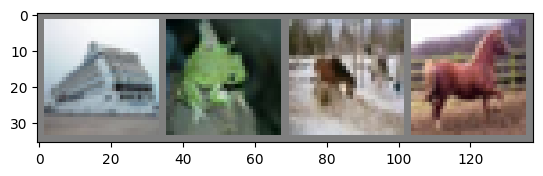

ship frog horse horse


In [5]:
def imshow(img):
    img = img / 2 + 0.5
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()


dataiter = iter(train_loader)
images, labels = next(dataiter)

imshow(torchvision.utils.make_grid(images[:4]))

classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')
print(*[classes[labels[i]] for i in range(4)])

## 1. Задание сверточной сети (3 балла)

Теперь нам нужно задать сверточную нейронную сеть, которую мы будем обучать классифицировать изображения.

Используем сеть, основанную на одном блоке архитектуры ResNet.

<img src="https://i.ibb.co/2hg962h/basic-block.png" width="500"/>

__Указания:__

- Все сверточные слои должны иметь 32 выходных канала, а также не должны изменять ширину и высоту изображения.
- Выход блока сократите до размерности 32х4х4, применив average pooling.
- Для получения итоговых логитов, распрямите выход пулинга в вектор из 512 элементов, а затем пропустите его через линейный слой.

**Задание 1.1 (3 балла).**

Определите архитектуру сети соответственно схеме и указаниям выше.

Ключевые слова: <code>Conv2d</code>, <code>BatchNorm2d</code>, <code>AvgPool2d</code>.

In [6]:
n_classes = 10

class BasicBlockNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)

        self.conv2 = nn.Conv2d(32, 32, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(32)

        self.shortcut = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=32, kernel_size=1, stride=1, bias=False),
            nn.BatchNorm2d(32)
        )

        self.avgpool = nn.AvgPool2d(kernel_size=8) # 32x32 -> 4x4

        self.fc = nn.Linear(512, n_classes)

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))

        out = self.bn2(self.conv2(out))

        out += self.shortcut(x)
        out = F.relu(out)

        out = self.avgpool(out)

        out = torch.flatten(out, 1)
        out = self.fc(out)

        return out

In [7]:
net = BasicBlockNet()
net

BasicBlockNet(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (shortcut): Sequential(
    (0): Conv2d(3, 32, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
  (avgpool): AvgPool2d(kernel_size=8, stride=8, padding=0)
  (fc): Linear(in_features=512, out_features=10, bias=True)
)

Проверим, что выход сети имеет корректную размерность:

In [6]:
assert net(torch.zeros((10, 3, 32, 32))).shape == (10, 10)

Чтобы проводить вычисления на GPU, в PyTorch необходимо руками перекладывать объекты, с которыми вы хотите проводить вычисления, на графический ускоритель. Это делается следующим образрм:

In [8]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(device)

cuda:0


In [9]:
net = net.to(device)

Подключение GPU в google.colab:

**Среда выполнения** -> **Сменить среду выполнения** -> **Аппаратный ускоритель** -> **GPU**

## 2. Обучение и тестирование модели (3 балла)

**Задание 2.1 (2 балла).** Переходим к обучению модели. Заполните пропуски в функциях <code>test</code> и <code>train_epoch</code>. В качестве функции потерь будем использовать [кросс-энтропию](https://pytorch.org/docs/stable/generated/torch.nn.functional.cross_entropy.html), а в качестве метрики качества accuracy.

In [10]:
!pip install torchmetrics
from torchmetrics.classification import Accuracy

criterion = nn.CrossEntropyLoss()

acc_metric = Accuracy(task="multiclass", num_classes=10).to(device)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.2/983.2 kB 59.6 MB/s eta 0:00:00


In [11]:
def test(model, loader):
    loss_log = []
    acc_log = []
    model.eval()

    with torch.no_grad():
      for data, target in loader:
        data = data.to(device)
        target = target.to(device)

        output = model(data) # forward

        loss = criterion(output, target)
        loss_log.append(loss.item())

        acc = acc_metric(output, target)

        acc_log.append(acc.item())

    return np.mean(loss_log), np.mean(acc_log)

def train_epoch(model, optimizer, train_loader):
    loss_log = []
    acc_log = []
    model.train()

    for data, target in train_loader:
      data = data.to(device)
      target = target.to(device)

      optimizer.zero_grad()

      output = model(data) # forward

      loss = criterion(output, target)
      loss_log.append(loss.item())

      loss.backward()
      optimizer.step()

      acc = acc_metric(output, target)

      acc_log.append(acc.item())

    return loss_log, acc_log

def train(model, optimizer, n_epochs, train_loader, val_loader, scheduler=None):
    train_loss_log, train_acc_log, val_loss_log, val_acc_log = [], [], [], []

    for epoch in range(n_epochs):
        train_loss, train_acc = train_epoch(model, optimizer, train_loader)
        val_loss, val_acc = test(model, val_loader)

        train_loss_log.extend(train_loss)
        train_acc_log.extend(train_acc)

        val_loss_log.append(val_loss)
        val_acc_log.append(val_acc)

        print(f"Epoch {epoch}")
        print(f" train loss: {np.mean(train_loss)}, train acc: {np.mean(train_acc)}")
        print(f" val loss: {val_loss}, val acc: {val_acc}\n")

        if isinstance(scheduler, torch.optim.lr_scheduler.ReduceLROnPlateau):
          scheduler.step(val_loss)
        elif scheduler is not None:
          scheduler.step()

    return train_loss_log, train_acc_log, val_loss_log, val_acc_log

Запустим обучение модели. В качестве оптимизатора будем использовать стохастический градиентный спуск, который является де-факто стандартом в задачах компьютерного зрения (наравне с <code>Adam</code>).

__Замечание:__ Для достижения наилучшего качества в нашем случае потребуется обучать модель несколько сотен эпох. Однако в целях экономии вашего времени и сил, во всех экспериментах мы ограничимся 20 эпохами.

In [10]:
optimizer = optim.SGD(net.parameters(), lr=0.1, momentum=0.9)
train_loss_log, train_acc_log, val_loss_log, val_acc_log = train(net, optimizer, 20, train_loader, val_loader)

Epoch 0
 train loss: 1.4742902952094836, train acc: 0.47807848006759307
 val loss: 1.1960267515892677, val acc: 0.5826241135597229

Epoch 1
 train loss: 1.1650060628842174, train acc: 0.5923666427732603
 val loss: 1.2805976421275038, val acc: 0.5575354609083623

Epoch 2
 train loss: 1.0467123181118172, train acc: 0.6360382932413648
 val loss: 1.1436998993792433, val acc: 0.6036790780564572

Epoch 3
 train loss: 0.9848819704116807, train acc: 0.6595635283363802
 val loss: 1.0242943758660175, val acc: 0.6448359928232559

Epoch 4
 train loss: 0.9429759525947641, train acc: 0.6761719769707981
 val loss: 0.9765380362246899, val acc: 0.661591311972192

Epoch 5
 train loss: 0.9127479041952101, train acc: 0.6830683599006542
 val loss: 0.962740617102765, val acc: 0.6639406027946066

Epoch 6
 train loss: 0.8986643062431154, train acc: 0.6876754700810643
 val loss: 0.9564278848627781, val acc: 0.6724290779296388

Epoch 7
 train loss: 0.8744507893456838, train acc: 0.6966407678244972
 val loss: 0.

Посчитайте точность на тестовой выборке:

In [21]:
test_loss, test_acc = test(net, test_loader)
print("Test loss:", test_loss)
print("Test accuracy:", test_acc)

Test loss: 0.8545042037204572
Test accuracy: 0.7102906050955414


Если вы все сделали правильно, у вас должна была получиться точность $\ge 67\%$.

**Задание 2.2 (1 балл).** Постройте графики зависимости функции потерь и точности классификации от номера шага оптимизатора. На каждом графике расположите данные и для обучающей и для валидационной выборки, итого у вас должно получиться два графика. Обратите внимание, что на обучающей выборке эти данные считаются по каждому батчу, на валидационной же они считаются по всей выборке раз в эпоху.

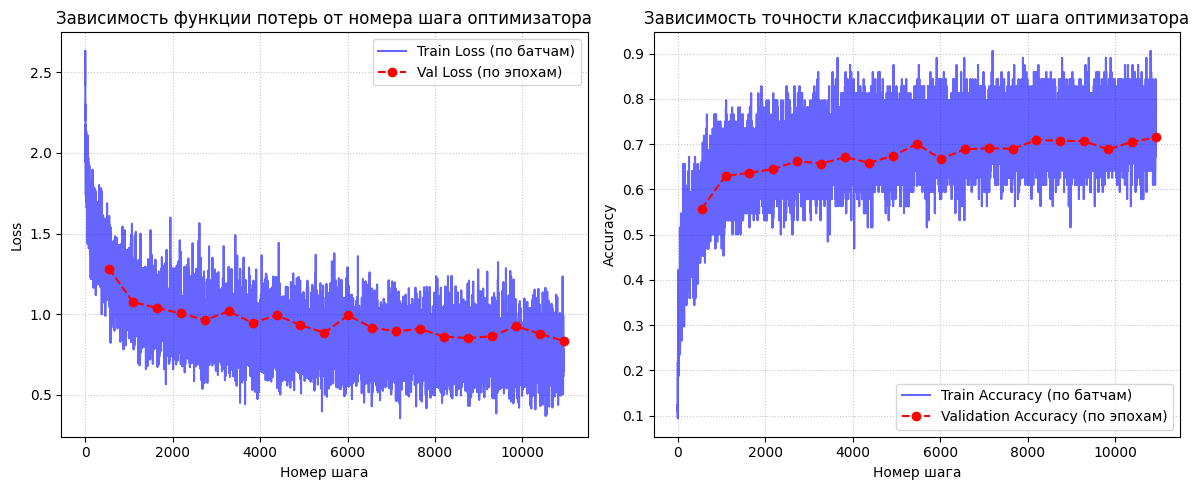

In [24]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)

# train
plt.plot(train_loss_log, label='Train Loss (по батчам)', alpha=0.6, color='blue')
# validation
batches_per_epoch = len(train_loss_log) // len(val_loss_log)
steps_val = np.arange(0, len(val_loss_log)) * batches_per_epoch
plt.plot(steps_val, val_loss_log, label='Val Loss (по эпохам)', marker='o', linestyle='--', color='red')

plt.title('Зависимость функции потерь от номера шага оптимизатора')
plt.xlabel('Номер шага')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)

plt.subplot(1, 2, 2)

plt.plot(train_acc_log, label='Train Accuracy (по батчам)', alpha=0.6, color='blue')
plt.plot(steps_val, val_acc_log, label='Validation Accuracy (по эпохам)', marker='o', linestyle='--', color='red')
plt.title('Зависимость точности классификации от шага оптимизатора')
plt.xlabel('Номер шага')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)

plt.tight_layout()
plt.show()

## 3. Расписание длины шага (2 балла)

С курса "Машинное обучение 1" вы уже должны знать, что сходимость стохастического градиентного спуска мы можем теоретически гарантировать только если будем определенным образом со временем уменьшать длину шага. На практике при обучении нейронных сетей такая техника оказывается очень полезной, однако теоретически обоснованными способами уменьшения длины шага фантазия не ограничивается.

Одним из простейших способов является кусочно постоянная функция: на нескольких фиксированных эпохах уменьшаем длину шага в константу раз.

In [26]:
net = BasicBlockNet().to(device)
optimizer = optim.SGD(net.parameters(), lr=0.1, momentum=0.9)
scheduler = optim.lr_scheduler.MultiStepLR(optimizer, milestones=[10, 15], gamma=0.1) # после 10й и 15й эпохи lr снизится на 0.1
tr_loss_log, tr_acc_log, val_loss_log, val_acc_log = train(net, optimizer, 20, train_loader, val_loader, scheduler)

Epoch 0
 train loss: 1.556288020702341, train acc: 0.44534310529611226
 val loss: 1.3138397176214989, val acc: 0.5371675531914893

Epoch 1
 train loss: 1.2364486709809173, train acc: 0.5673682749598292
 val loss: 1.1931646737646548, val acc: 0.5855496453477981

Epoch 2
 train loss: 1.0848296670416808, train acc: 0.6234819796447126
 val loss: 1.1421798647718227, val acc: 0.5945478723404255

Epoch 3
 train loss: 1.0178666192173305, train acc: 0.6471418777593093
 val loss: 0.9898637038596133, val acc: 0.6532801417594261

Epoch 4
 train loss: 0.9719826020096076, train acc: 0.6661334552102377
 val loss: 1.0024838964989844, val acc: 0.6498891843126176

Epoch 5
 train loss: 0.938024625372843, train acc: 0.6745192935959294
 val loss: 1.0757743805012805, val acc: 0.6265957446808511

Epoch 6
 train loss: 0.9159914287832145, train acc: 0.6822236549701726
 val loss: 0.9663305652902482, val acc: 0.6673980497299357

Epoch 7
 train loss: 0.8972286393481155, train acc: 0.6878876665392567
 val loss: 1.

Посчитайте точность на тестовой выборке:

In [28]:
test_loss, test_acc = test(net, test_loader)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

Test Loss: 0.8261
Test Accuracy: 0.7141


**Задание 3.0 (0.5 баллов).** Здесь может возникнуть вопрос: а что будет, если мы не будем уменьшать длину шага в процессе обучения, а сразу возьмем констатную, равную значению нашей кусочно-постоянной функции на последних эпохах, то есть $0.001$ в нашем случае. Запустите обучение и проверьте, что в таком случае мы получим худшее качество на тестовой выборке.

In [29]:
net = BasicBlockNet().to(device)
optimizer = optim.SGD(net.parameters(), lr=0.001, momentum=0.9)
tr_loss_log, tr_acc_log, val_loss_log, val_acc_log = train(net, optimizer, 20, train_loader, val_loader)

Epoch 0
 train loss: 1.782448248191987, train acc: 0.3755549751426446
 val loss: 1.584624573524962, val acc: 0.44204343975858484

Epoch 1
 train loss: 1.5230852173712832, train acc: 0.46283706581352835
 val loss: 1.4624996651994422, val acc: 0.4829122340425532

Epoch 2
 train loss: 1.419538243161259, train acc: 0.4991022460094536
 val loss: 1.377139243673771, val acc: 0.5116134751350322

Epoch 3
 train loss: 1.3477580772893303, train acc: 0.5226642073181473
 val loss: 1.32888821845359, val acc: 0.5303634752618506

Epoch 4
 train loss: 1.2882513692653592, train acc: 0.5491805954868658
 val loss: 1.260544247576531, val acc: 0.5569148936170213

Epoch 5
 train loss: 1.247292428827373, train acc: 0.5637772591066099
 val loss: 1.2215838800085352, val acc: 0.5756870566530431

Epoch 6
 train loss: 1.2028493209992293, train acc: 0.5790186732517082
 val loss: 1.181533494908759, val acc: 0.5910682624958931

Epoch 7
 train loss: 1.162876390451923, train acc: 0.5959699007885112
 val loss: 1.1595652

In [30]:
test_loss, test_acc = test(net, test_loader)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

Test Loss: 0.9594
Test Accuracy: 0.6681


**Задание 3.1 (1.5 балла).** Изучите, какие еще способы уменьшения длины шага представлены в <code>torch.optim.lr_scheduler</code>. Выберите несколько из них, объясните, как они устроены, и обучите модель с ними. Удалось ли добиться улучшения качества на тестовой выборке?

In [13]:
net = BasicBlockNet().to(device)
optimizer = optim.SGD(net.parameters(), lr=0.1, momentum=0.9)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.3, patience=3)
tr_loss_log, tr_acc_log, val_loss_log, val_acc_log = train(net, optimizer, 20, train_loader, val_loader, scheduler)

test_loss, test_acc = test(net, test_loader)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

Epoch 0
 train loss: 1.4968485026952336, train acc: 0.4706230413107375
 val loss: 1.306218617266797, val acc: 0.5362810284533399

Epoch 1
 train loss: 1.1745401927060575, train acc: 0.5892367458866545
 val loss: 1.126969750384067, val acc: 0.6108377659574468

Epoch 2
 train loss: 1.0478653531841648, train acc: 0.6335449856203696
 val loss: 1.0491860242600137, val acc: 0.6389406029214251

Epoch 3
 train loss: 0.9945541048180686, train acc: 0.6562132737318385
 val loss: 0.9797209858894348, val acc: 0.6636081561129143

Epoch 4
 train loss: 0.954189796879261, train acc: 0.6678187842778793
 val loss: 0.9752610744313991, val acc: 0.6628324468085106

Epoch 5
 train loss: 0.9287025201691134, train acc: 0.6776206254741174
 val loss: 0.9764118468507808, val acc: 0.6674867021276596

Epoch 6
 train loss: 0.9062001152709808, train acc: 0.6865451162650337
 val loss: 0.9503604569333665, val acc: 0.6776817375041069

Epoch 7
 train loss: 0.8841975487128472, train acc: 0.6940740075582125
 val loss: 0.98

In [14]:
net = BasicBlockNet().to(device)
optimizer = optim.SGD(net.parameters(), lr=0.1, momentum=0.9)
scheduler = optim.lr_scheduler.OneCycleLR(optimizer, max_lr=0.1, epochs=20, steps_per_epoch=len(train_loader))
tr_loss_log, tr_acc_log, val_loss_log, val_acc_log = train(net, optimizer, 20, train_loader, val_loader, scheduler)

test_loss, test_acc = test(net, test_loader)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

Epoch 0
 train loss: 1.5153030247531383, train acc: 0.46078039305301643
 val loss: 1.3205952274038437, val acc: 0.5302969859001484

Epoch 1
 train loss: 1.246892097663182, train acc: 0.5607493797647451
 val loss: 1.2187672505987452, val acc: 0.5720523050490846

Epoch 2
 train loss: 1.1258140012376705, train acc: 0.6050494581297503
 val loss: 1.10810072624937, val acc: 0.6100620567798615

Epoch 3
 train loss: 1.0555936663634597, train acc: 0.6302069730688928
 val loss: 1.099382430695473, val acc: 0.6135859929500742

Epoch 4
 train loss: 0.9976183877784548, train acc: 0.6541729237087466
 val loss: 1.0067425991626495, val acc: 0.6452570922831271

Epoch 5
 train loss: 0.9706221769889051, train acc: 0.658624967338834
 val loss: 0.958224906819932, val acc: 0.6674423759287976

Epoch 6
 train loss: 0.9417270134310399, train acc: 0.6734011817239974
 val loss: 0.9569874611306698, val acc: 0.6654476950777338

Epoch 7
 train loss: 0.9136513906379504, train acc: 0.6829377774564614
 val loss: 0.9375

In [21]:
net = BasicBlockNet().to(device)
optimizer = optim.SGD(net.parameters(), lr=0.1, momentum=0.9)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=20)
tr_loss_log, tr_acc_log, val_loss_log, val_acc_log = train(net, optimizer, 20, train_loader, val_loader, scheduler)

test_loss, test_acc = test(net, test_loader)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

Epoch 0
 train loss: 1.5478831853247648, train acc: 0.4505255941499086
 val loss: 1.311199831455312, val acc: 0.5401374114320633

Epoch 1
 train loss: 1.223566645351145, train acc: 0.5727507182187529
 val loss: 1.1290400045983335, val acc: 0.6058510638297873

Epoch 2
 train loss: 1.0982210830099186, train acc: 0.6184423151792077
 val loss: 1.1268375787329166, val acc: 0.6114583333756062

Epoch 3
 train loss: 1.0349412659622415, train acc: 0.6439222054899938
 val loss: 1.0963703515681815, val acc: 0.6165115248649679

Epoch 4
 train loss: 0.9825768866312351, train acc: 0.6595023178531221
 val loss: 0.9594799244657476, val acc: 0.6695700353764473

Epoch 5
 train loss: 0.9504783895595418, train acc: 0.6712669757428074
 val loss: 0.9654622968207014, val acc: 0.6726285460147452

Epoch 6
 train loss: 0.9226265403644694, train acc: 0.6773023308957953
 val loss: 0.9269923704735776, val acc: 0.6828900710065314

Epoch 7
 train loss: 0.9019071373686712, train acc: 0.6859697374826811
 val loss: 0.9

Your answers here:

ранее использовался MultiStepLR

здесь я использовала
- ReduceLROnPlateau: уменьшает lr, когда метрика (в данном случае val_loss) перестает улучшаться (снижаться) -> test accuracy выросла
- OneCycleLR: lr сначала линейно растет до максимума, а затем плавно снижается -> test accuracy также выросла, но меньше, чем при ReduceLROnPlateau
- CosineAnnealingLR: lr плавно колеблется по косинусной кривой -> test accuracy выросла до наибольших 73%

## 4. Аугментации данных (2 балла)

Еще одной стандартной техникой, применяющейся в глубинном обучении, а особенно часто в компьютерном зрении, являются аугментации данных. Суть аугментаций состоит в том, что мы можем некоторым синтетическим образом видоизменять объекты обучающей выборки, тем самым расширяя ее, а также делая итоговую модель более устойчивой к таким изменениям.

Простейшая аугментация, которую можно применить к картинкам — разворот картинки по горизонтальной оси. То есть при обучении модели с вероятностью $0.5$ мы будем разворачивать картинку из обучающей выборки.

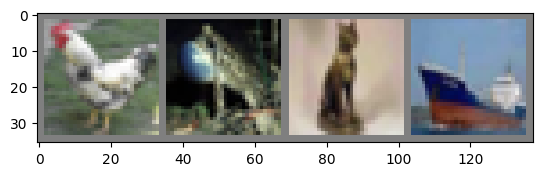

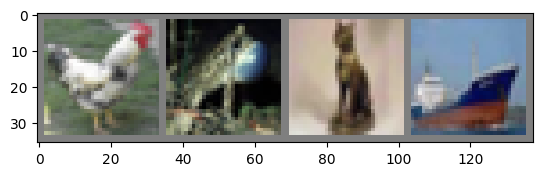

In [18]:
dataiter = iter(train_loader)
images, labels = next(dataiter)

imshow(torchvision.utils.make_grid(images[:4]))

imshow(torchvision.utils.make_grid(transforms.functional.hflip(images[:4])))

Наиболее удобным способом работы с аугментациями в PyTorch является их задание в списке <code>transforms</code>, который затем передается в загрузчик данных. Обучим нашу сеть, применяя горизонтальные повороты:

In [22]:
transform = transforms.Compose(
        [transforms.RandomHorizontalFlip(),
         transforms.ToTensor(),
         transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))]
)

train_loader, val_loader, test_loader = get_cifar10_data(batch_size=64, transform_train=transform)

net = BasicBlockNet().to(device)
optimizer = optim.SGD(net.parameters(), lr=0.1, momentum=0.9)
# scheduler = optim.lr_scheduler.MultiStepLR(optimizer, milestones=[10, 15], gamma=0.1)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=20)
tr_loss_log, tr_acc_log, val_loss_log, val_acc_log = train(net, optimizer, 20, train_loader, val_loader, scheduler)

Epoch 0
 train loss: 1.4658163655174716, train acc: 0.4837996213266139
 val loss: 1.2463055864293524, val acc: 0.5585771276595745

Epoch 1
 train loss: 1.1483691781486847, train acc: 0.598544822423506
 val loss: 1.239832501715802, val acc: 0.5697916667512123

Epoch 2
 train loss: 1.056197971704891, train acc: 0.6338755223607232
 val loss: 1.1490016807901098, val acc: 0.6017287234042553

Epoch 3
 train loss: 0.9982513451924926, train acc: 0.655731751125517
 val loss: 0.9594924008592646, val acc: 0.6710328013338941

Epoch 4
 train loss: 0.9562092258899696, train acc: 0.6689042504570384
 val loss: 0.9533563857382916, val acc: 0.6733377659574468

Epoch 5
 train loss: 0.9234085748792784, train acc: 0.6778695482004713
 val loss: 0.9323429219266202, val acc: 0.6746010638297872

Epoch 6
 train loss: 0.9034910049473346, train acc: 0.6863043549073897
 val loss: 0.9054344697201505, val acc: 0.6876773050490846

Epoch 7
 train loss: 0.879260976800535, train acc: 0.6948493405277594
 val loss: 0.9467

Посчитайте точность на тестовой выборке:

In [23]:
test_loss, test_acc = test(net, test_loader)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

Test Loss: 0.7835
Test Accuracy: 0.7338


**Задание 4.1 (2 балла).** Изучите, какие еще способы аугментаций изображений представлены в <code>torchvision.transforms</code>. Выберите несколько из них, объясните, как они устроены, и обучите модель с ними (по отдельности и вместе). Удалось ли добиться улучшения качества на тестовой выборке?

In [12]:
transform = transforms.Compose(
        [transforms.RandomHorizontalFlip(),
         transforms.RandomRotation(degrees=(0, 180)),
         transforms.ToTensor(),
         transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))]
)

train_loader, val_loader, test_loader = get_cifar10_data(batch_size=64, transform_train=transform)

net = BasicBlockNet().to(device)
optimizer = optim.SGD(net.parameters(), lr=0.1, momentum=0.9)
# scheduler = optim.lr_scheduler.MultiStepLR(optimizer, milestones=[10, 15], gamma=0.1)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=20)
tr_loss_log, tr_acc_log, val_loss_log, val_acc_log = train(net, optimizer, 20, train_loader, val_loader, scheduler)

test_loss, test_acc = test(net, test_loader)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

Epoch 0
 train loss: 1.7971076647150015, train acc: 0.3568694502714565
 val loss: 1.6437010161420131, val acc: 0.4068040780564572

Epoch 1
 train loss: 1.6302689863079427, train acc: 0.41785959128487915
 val loss: 1.581671458102287, val acc: 0.43840868790098964

Epoch 2
 train loss: 1.5542304456996743, train acc: 0.44859542304026795
 val loss: 1.5267811186770175, val acc: 0.456781914893617

Epoch 3
 train loss: 1.4902668611658993, train acc: 0.4700680660591265
 val loss: 1.5298234939575195, val acc: 0.46050531914893617

Epoch 4
 train loss: 1.4552861382364137, train acc: 0.4848646839750314
 val loss: 1.402668204713375, val acc: 0.4999113474754577

Epoch 5
 train loss: 1.4188953165162417, train acc: 0.495103160086236
 val loss: 1.4728392601013183, val acc: 0.4801640070499258

Epoch 6
 train loss: 1.393036418466725, train acc: 0.5096753395453667
 val loss: 1.3525784030873724, val acc: 0.5245124114320633

Epoch 7
 train loss: 1.3670648504218845, train acc: 0.5140539305301646
 val loss: 1.

In [13]:
transform = transforms.Compose(
        [transforms.RandomHorizontalFlip(),
         transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2),
         transforms.ToTensor(),
         transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))]
)

train_loader, val_loader, test_loader = get_cifar10_data(batch_size=64, transform_train=transform)

net = BasicBlockNet().to(device)
optimizer = optim.SGD(net.parameters(), lr=0.1, momentum=0.9)
# scheduler = optim.lr_scheduler.MultiStepLR(optimizer, milestones=[10, 15], gamma=0.1)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=20)
tr_loss_log, tr_acc_log, val_loss_log, val_acc_log = train(net, optimizer, 20, train_loader, val_loader, scheduler)

test_loss, test_acc = test(net, test_loader)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

Epoch 0
 train loss: 1.567402326428694, train acc: 0.4479384303528822
 val loss: 1.3327525930201753, val acc: 0.5360815603682335

Epoch 1
 train loss: 1.2424897566791862, train acc: 0.5677477801303759
 val loss: 1.2282898857238445, val acc: 0.5733599289934685

Epoch 2
 train loss: 1.1341755738859856, train acc: 0.6084568425331952
 val loss: 1.2602513868758018, val acc: 0.5678413120990103

Epoch 3
 train loss: 1.0882103396290181, train acc: 0.624224667030453
 val loss: 1.1413366015921247, val acc: 0.606626773134191

Epoch 4
 train loss: 1.0368997452463922, train acc: 0.6436447179731547
 val loss: 1.1047253804003938, val acc: 0.6163342199427017

Epoch 5
 train loss: 1.0019517895072645, train acc: 0.6544055235887141
 val loss: 1.0187106530717078, val acc: 0.6425531914893617

Epoch 6
 train loss: 0.974057309588305, train acc: 0.6664966375343978
 val loss: 0.9948684192718343, val acc: 0.6556959220703612

Epoch 7
 train loss: 0.9530619099545522, train acc: 0.6721769718409021
 val loss: 1.039

In [14]:
transform = transforms.Compose(
        [transforms.RandomHorizontalFlip(),
         transforms.RandomCrop(32, padding=4),
         transforms.ToTensor(),
         transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))]
)

train_loader, val_loader, test_loader = get_cifar10_data(batch_size=64, transform_train=transform)

net = BasicBlockNet().to(device)
optimizer = optim.SGD(net.parameters(), lr=0.1, momentum=0.9)
# scheduler = optim.lr_scheduler.MultiStepLR(optimizer, milestones=[10, 15], gamma=0.1)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=20)
tr_loss_log, tr_acc_log, val_loss_log, val_acc_log = train(net, optimizer, 20, train_loader, val_loader, scheduler)

test_loss, test_acc = test(net, test_loader)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

Epoch 0
 train loss: 1.679488244178744, train acc: 0.39287754637231775
 val loss: 1.4901196626906699, val acc: 0.4590203900286492

Epoch 1
 train loss: 1.4290722647794203, train acc: 0.4881047597206053
 val loss: 1.3639646017805058, val acc: 0.5192597518575952

Epoch 2
 train loss: 1.2979953357680842, train acc: 0.5412558761767539
 val loss: 1.3987614687452925, val acc: 0.5217198581137555

Epoch 3
 train loss: 1.2301227873160592, train acc: 0.5685557586837294
 val loss: 1.18591365104026, val acc: 0.5850177304541812

Epoch 4
 train loss: 1.1702935746862422, train acc: 0.5909343170073612
 val loss: 1.1445996748640181, val acc: 0.5991578013338941

Epoch 5
 train loss: 1.1277985524869707, train acc: 0.6064164925101034
 val loss: 1.1692400019219582, val acc: 0.5791223404255319

Epoch 6
 train loss: 1.1048846187059798, train acc: 0.6121784408306074
 val loss: 1.1109884353394204, val acc: 0.6061835106382979

Epoch 7
 train loss: 1.0797669582436682, train acc: 0.6190095324838837
 val loss: 1.1

In [15]:
transform = transforms.Compose(
        [transforms.RandomHorizontalFlip(),
         transforms.AutoAugment(policy=transforms.AutoAugmentPolicy.CIFAR10),
         transforms.ToTensor(),
         transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))]
)

train_loader, val_loader, test_loader = get_cifar10_data(batch_size=64, transform_train=transform)

net = BasicBlockNet().to(device)
optimizer = optim.SGD(net.parameters(), lr=0.1, momentum=0.9)
# scheduler = optim.lr_scheduler.MultiStepLR(optimizer, milestones=[10, 15], gamma=0.1)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=20)
tr_loss_log, tr_acc_log, val_loss_log, val_acc_log = train(net, optimizer, 20, train_loader, val_loader, scheduler)

test_loss, test_acc = test(net, test_loader)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

Epoch 0
 train loss: 1.8127563237272188, train acc: 0.35601658397226493
 val loss: 1.6430031568446057, val acc: 0.42136524826922317

Epoch 1
 train loss: 1.5233062819545404, train acc: 0.46768493729709926
 val loss: 1.4917496990650259, val acc: 0.4693927304541811

Epoch 2
 train loss: 1.4293974215195426, train acc: 0.5048111451609261
 val loss: 1.428369038663012, val acc: 0.5067154255319148

Epoch 3
 train loss: 1.3628159207879298, train acc: 0.5282384435045218
 val loss: 1.3182013344257435, val acc: 0.5461214539852548

Epoch 4
 train loss: 1.3222156440536108, train acc: 0.5397949856203696
 val loss: 1.3344374796177478, val acc: 0.5367242908224147

Epoch 5
 train loss: 1.295030290073625, train acc: 0.5507924719092179
 val loss: 1.2937616703358101, val acc: 0.5447251773895101

Epoch 6
 train loss: 1.2653863277470172, train acc: 0.5621980281590979
 val loss: 1.3061089918968525, val acc: 0.546875

Epoch 7
 train loss: 1.245148521672655, train acc: 0.5706205928674346
 val loss: 1.265559958

In [16]:
transform = transforms.Compose(
        [transforms.RandomHorizontalFlip(),
         transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
         transforms.RandomCrop(32, padding=4),
         transforms.ToTensor(),
         transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))]
)

train_loader, val_loader, test_loader = get_cifar10_data(batch_size=64, transform_train=transform)

net = BasicBlockNet().to(device)
optimizer = optim.SGD(net.parameters(), lr=0.1, momentum=0.9)
# scheduler = optim.lr_scheduler.MultiStepLR(optimizer, milestones=[10, 15], gamma=0.1)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=20)
tr_loss_log, tr_acc_log, val_loss_log, val_acc_log = train(net, optimizer, 20, train_loader, val_loader, scheduler)

test_loss, test_acc = test(net, test_loader)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

Epoch 0
 train loss: 1.7376666772953988, train acc: 0.3711804648422018
 val loss: 1.5477165262749855, val acc: 0.44242021276595744

Epoch 1
 train loss: 1.4764414125648233, train acc: 0.47370805039702213
 val loss: 1.4278048682720104, val acc: 0.49452570917758537

Epoch 2
 train loss: 1.3415868587424158, train acc: 0.5263164337635912
 val loss: 1.337519521155256, val acc: 0.5324689716734785

Epoch 3
 train loss: 1.2626679923242363, train acc: 0.5573746409451068
 val loss: 1.2733472187468347, val acc: 0.5576684397585848

Epoch 4
 train loss: 1.2112700919564507, train acc: 0.5745584682529108
 val loss: 1.194191270178937, val acc: 0.5846187944107867

Epoch 5
 train loss: 1.1726832643723357, train acc: 0.5899631104260084
 val loss: 1.2813062226518672, val acc: 0.5447916667512123

Epoch 6
 train loss: 1.1391725134805961, train acc: 0.605416721029299
 val loss: 1.1326421341997512, val acc: 0.6038785461415636

Epoch 7
 train loss: 1.113102950714188, train acc: 0.613847447160829
 val loss: 1.1

Your answers here:

ранее использовали RandomHorizontalFlip

здесь я использовала:
- RandomRotation: случайный поворот в заданном диапазоне углов -> test acc снизилась
- ColorJitter: рандомно меняет яркость, контрастность, насыщенность оттенка -> test acc снизилась незначительно
- RandomCrop: случайно вырезает часть изображения -> test acc снизилась
- AutoAugment: политика, состоящая из комбинаций преобразований, выполняющихся с заданной вероятностью - для CIFAR10 есть уже готовая)) -> test acc снизилась

при совместном использовании точность модели все равно не удалось улучшить

## Бонус. Логирование в comet (2 балла)

На практике специалиста по глубинному обучению часто встречаются ситуации, когда нейросеть учится на каком-то удаленном сервере. И обычно вам хочется отслеживать прогресс обучения, особенно когда время обучения модели исчисляется днями или неделями. Для таких целей существует несколько инструментов. ~~Вероятно, самый популярный из них — [wandb](https://wandb.ai/site)~~ Например: [TensorBoard](https://docs.pytorch.org/tutorials/recipes/recipes/tensorboard_with_pytorch.html), [comet](https://www.comet.com), [wandb](https://wandb.ai/). Выберите любой удобный из них.

Ваша задача состоит в том, чтобы разобраться как им пользоваться, и повторить задания 2.1 и 2.2 с его использованием. Обучение вы можете запускать в этом же ноутбуке, но теперь вам необходимо логировать значения функции потерь и точности на обучающей выборке и на валидационной. Результатом работы должны быть ваш код, публичная ссылка на страничку с графиками, идентичными графикам в задании 2.2 или выхлоп тензорбоард.

In [18]:
!pip install wandb
import wandb
wandb.login()

/usr/local/lib/python3.12/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: Logging into wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: You can find your API key in your browser here: https://wandb.ai/authorize
wandb: Paste an API key from your profile and hit enter:

 ··········


wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: sofyaandr2005 (sofyaandr2005-hse-university) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

In [19]:
def train(model, optimizer, n_epochs, train_loader, val_loader, scheduler=None):

    wandb.init(project="hse-dl-hw2", config={"epochs": n_epochs})
    wandb.watch(model, log="all")

    train_loss_log, train_acc_log, val_loss_log, val_acc_log = [], [], [], []

    for epoch in range(n_epochs):
        train_loss, train_acc = train_epoch(model, optimizer, train_loader)
        val_loss, val_acc = test(model, val_loader)

        train_loss_log.extend(train_loss)
        train_acc_log.extend(train_acc)

        val_loss_log.append(val_loss)
        val_acc_log.append(val_acc)

        wandb.log({
            "train_loss": np.mean(train_loss),
            "train_acc": np.mean(train_acc),
            "val_loss": val_loss,
            "val_acc": val_acc,
            "learning_rate": optimizer.param_groups[0]["lr"]
            })

        print(f"Epoch {epoch}")
        print(f" train loss: {np.mean(train_loss)}, train acc: {np.mean(train_acc)}")
        print(f" val loss: {val_loss}, val acc: {val_acc}\n")

        if isinstance(scheduler, torch.optim.lr_scheduler.ReduceLROnPlateau):
          scheduler.step(val_loss)
        elif scheduler is not None:
          scheduler.step()

    return train_loss_log, train_acc_log, val_loss_log, val_acc_log

In [22]:
transform = transforms.Compose(
        [transforms.RandomHorizontalFlip(),
         transforms.ToTensor(),
         transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))]
)

train_loader, val_loader, test_loader = get_cifar10_data(batch_size=64, transform_train=transform)

net = BasicBlockNet().to(device)
optimizer = optim.SGD(net.parameters(), lr=0.1, momentum=0.9)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=20)
tr_loss_log, tr_acc_log, val_loss_log, val_acc_log = train(net, optimizer, 20, train_loader, val_loader, scheduler)

learning_rate,████▇▇▇▆▆▅▄▄▃▃▂▂▂▁▁▁
train_acc,▁▄▅▅▆▆▆▆▇▇▇▇▇███████
train_loss,█▅▄▄▃▃▃▃▂▂▂▂▂▂▁▁▁▁▁▁
val_acc,▁▂▃▅▅▅▆▅▆▆▇▇▇▇▇█████
val_loss,█▇▆▅▄▄▃▄▃▃▂▂▂▂▂▁▁▁▁▁
learning_rate,0.00062
train_acc,0.75653
train_loss,0.70762
val_acc,0.7359
val_loss,0.77196


Epoch 0
 train loss: 1.4719378768417037, train acc: 0.4796413880597521
 val loss: 1.2249351978302, val acc: 0.5725398936170213

Epoch 1
 train loss: 1.1712935992960956, train acc: 0.5893714090152022
 val loss: 1.2720169775029446, val acc: 0.5561391843126176

Epoch 2
 train loss: 1.0728661692556558, train acc: 0.6265914730005769
 val loss: 1.1732811600603956, val acc: 0.5992907801841167

Epoch 3
 train loss: 1.0110818401551116, train acc: 0.653054811945781
 val loss: 1.0128364674588468, val acc: 0.6525487587807026

Epoch 4
 train loss: 0.9627710992718963, train acc: 0.6660926482577211
 val loss: 0.9751665934603265, val acc: 0.6619680851063829

Epoch 5
 train loss: 0.9291313463852654, train acc: 0.6774288325466665
 val loss: 0.9264143122003433, val acc: 0.6808067375041069

Epoch 6
 train loss: 0.9060449725531137, train acc: 0.6863941302900994
 val loss: 0.9082580908815912, val acc: 0.6840647162275112

Epoch 7
 train loss: 0.8847493083647008, train acc: 0.6945065617343408
 val loss: 0.931

ссылка на графики: https://wandb.ai/sofyaandr2005-hse-university/hse-dl-hw2/reports/Bonus-results--VmlldzoxNTIzNTE2MA?accessToken=dkcdlt76fihp8ozajlj0zeslfyyhn8uylm7732380evysg3bbpweykxp1mkte8xm